# 1 · Teacher training: fine-tune DINOv3-L on S2DS

**Project flow**

```
S2DS dataset ──► [Notebook 1] fine-tune DINOv3 ViT-L/16 (the TEACHER, ~300M params)
                         │  teacher_best.pth  (saved to Google Drive)
                         ▼
                 [Notebook 2] distil into MobileNetV3 (the STUDENT, ~3M params)
                         ► ONNX + int8 ► Raspberry Pi 3B+ with a camera
```

This notebook produces **`MyDrive/concrete_inspection/teacher/teacher_best.pth`**, the input of Notebook 2.

The model code (`model.py`), dataset loader + official S2DS metric (`s2ds_data.py`) and loss (`losses.py`) come
from the public repo `A-SHOJAEI/s2ds-defect-segmentation`; the training script below follows that repo's recipe and adds
GPU presets, partial fine-tuning for smaller GPUs, and automatic resume.

**Run order:** Runtime → Change runtime type → GPU, then run the cells top to bottom.
If Colab disconnects during training, reconnect and run everything again: training **resumes** from the last saved epoch.

## 1. Setup

In [1]:
import torch
print("PyTorch", torch.__version__, "| CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name}, {p.total_memory/1024**3:.1f} GB, compute capability {p.major}.{p.minor}")
    print("bf16:", p.major >= 8, "(False -> DINOv3 runs in fp32: slower, more memory)")
else:
    print("WARNING: no GPU. Runtime -> Change runtime type -> GPU")

PyTorch 2.11.0+cu130 | CUDA: True
GPU: NVIDIA L4, 22.0 GB, compute capability 8.9
bf16: True (False -> DINOv3 runs in fp32: slower, more memory)


In [2]:
!pip install -q "timm>=1.0.27" scikit-image opencv-python-headless

In [3]:
import os, sys

DRIVE_DIR = "/content/drive/MyDrive/concrete_inspection"      # everything we keep goes here
REPO      = "/content/s2ds-defect-segmentation"
DATA_ROOT = "/content/s2ds_full"

# 1. code library: model.py (DINOv3-L teacher), s2ds_data.py (dataset + official metric), losses.py
if not os.path.exists(REPO):
    !git clone -q https://github.com/A-SHOJAEI/s2ds-defect-segmentation.git {REPO}

# 2. Google Drive (checkpoints survive Colab disconnects there)
from google.colab import drive
drive.mount("/content/drive")
os.makedirs(DRIVE_DIR, exist_ok=True)

# 3. S2DS dataset
if not os.path.exists(DATA_ROOT + "/val"):
    !gdown 1PQ50QKfy2vnDOHSmw5bpBFi33hZsSXuM -O /content/s2ds_dataset.zip
    !unzip -q /content/s2ds_dataset.zip -d {DATA_ROOT}

os.environ["S2DS_ROOT"] = DATA_ROOT
sys.path.insert(0, REPO)
os.chdir("/content")
import s2ds_data as D
for split, expected in (("train", 563), ("val", 87), ("test", 93)):
    n = len(D.list_split(split))
    print(f"{split:5s}: {n} images (expected {expected})" + ("" if n == expected else "  <-- CHECK THE DATASET FOLDER"))

Mounted at /content/drive
Failed to retrieve file url:

	Too many users have viewed or downloaded this file recently. Please
	try accessing the file again later. If the file you are trying to
	access is particularly large or is shared with many people, it may
	take up to 24 hours to be able to view or download the file. If you
	still can't access a file after 24 hours, contact your domain
	administrator.

You may still be able to access the file from the browser:

	https://drive.google.com/uc?id=1PQ50QKfy2vnDOHSmw5bpBFi33hZsSXuM

but Gdown can't. Please check connections and permissions.
unzip:  cannot find or open /content/s2ds_dataset.zip, /content/s2ds_dataset.zip.zip or /content/s2ds_dataset.zip.ZIP.
train: 0 images (expected 563)  <-- CHECK THE DATASET FOLDER
val  : 0 images (expected 87)  <-- CHECK THE DATASET FOLDER
test : 0 images (expected 93)  <-- CHECK THE DATASET FOLDER


### Configuration

The preset is chosen from your GPU. **Full fine-tuning** (all 24 ViT blocks) is the repo's recipe and gives the best teacher,
but needs a bf16 GPU with ≥ 20 GB. On a T4 we fine-tune only the **last 4 blocks** at 512 px crops.

| GPU | train_blocks | crop | precision | notes |
|---|---|---|---|---|
| A100 (40/80 GB) | 24 (full) | 768 | bf16 | repo recipe |
| L4 / A10 (24 GB) | 24 (full) | 768 | bf16 | + gradient checkpointing |
| T4 (16 GB) | 4 | 512 | fp32 | weaker teacher, still much stronger than the student |

The repo author reports ~135 s/epoch for the full recipe on a 24 GB GPU (70 epochs ≈ 3 h). Your epoch time is printed
after epoch 1; multiply by the number of epochs for your own estimate.

`train_blocks=0` trains only the head (backbone frozen): fastest, weakest, and saves a small (~18 MB) checkpoint.

In [4]:
p = torch.cuda.get_device_properties(0)
mem_gb, bf16 = p.total_memory / 1024**3, p.major >= 8
if bf16 and mem_gb > 30:
    PRESET = dict(train_blocks=24, crop=768, batch=2, accum=4, epochs=50, grad_ckpt=False, tta=True)
elif bf16 and mem_gb > 20:
    PRESET = dict(train_blocks=24, crop=768, batch=2, accum=4, epochs=50, grad_ckpt=True, tta=True)
else:
    PRESET = dict(train_blocks=4, crop=512, batch=2, accum=4, epochs=30, grad_ckpt=True, tta=False)

# PRESET.update(epochs=40)        # <- override anything here if you want
TEACHER_DIR = f"{DRIVE_DIR}/teacher"
# Command-line arguments are built here as plain strings: Colab's `!` lines only substitute simple {NAME}s.
P = PRESET
COMMON_ARGS = (f"--repo {REPO} --data_root {DATA_ROOT} --train_blocks {P['train_blocks']} "
               f"--crop {P['crop']} --batch {P['batch']}" + (" --grad_ckpt" if P["grad_ckpt"] else ""))
SMOKE_ARGS = f"{COMMON_ARGS} --out /content/teacher_smoke --accum 1 --max_steps 3 --max_eval_images 3 --no_test"
FULL_ARGS = (f"{COMMON_ARGS} --out {TEACHER_DIR} --accum {P['accum']} --epochs {P['epochs']}"
             + (" --tta" if P["tta"] else ""))
print(p.name, "->", PRESET)
print("checkpoint will be saved to", f"{TEACHER_DIR}/teacher_best.pth")

NVIDIA L4 -> {'train_blocks': 24, 'crop': 768, 'batch': 2, 'accum': 4, 'epochs': 50, 'grad_ckpt': True, 'tta': True}
checkpoint will be saved to /content/drive/MyDrive/concrete_inspection/teacher/teacher_best.pth


## 2. Training script

In [5]:
%%writefile train_teacher.py
"""Fine-tune the TEACHER: DINOv3 ViT-L/16 + multi-scale segmentation head on S2DS (7 classes).

Follows the repo's training recipe (train.py) with additions for Colab:
  * works on any GPU: bf16 on Ampere+ (A100/L4), fp32 on T4 (DINOv3 gives NaNs in fp16)
  * --train_blocks N : fine-tune only the last N of the 24 ViT blocks (0 = frozen backbone,
                       head only; 24 = full fine-tune). Fewer blocks = less GPU memory/time.
  * --grad_ckpt      : gradient checkpointing (trades ~30% speed for much less memory)
  * automatic RESUME from <out>/<tag>_last.pt (Colab disconnects; just re-run the cell)
  * class weights computed automatically from the train labels

Output: <out>/<tag>_best.pth   (EMA weights with the best val mIoU)  <- the teacher checkpoint
        <out>/<tag>_result.json (val + official test metrics)

The checkpoint is {"ema": state_dict, "args": ..., "val": ...}. With --train_blocks 0 it holds
only the head ("head.*" keys, ~18 MB) because the backbone is the unchanged pretrained DINOv3;
otherwise it holds the whole model (~1.2 GB). The distillation notebook accepts both.
"""
from __future__ import annotations

import argparse
import copy
import json
import os
import sys
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset


def log(msg):
    print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)


def _worker_init(_):
    import cv2
    cv2.setNumThreads(0)
    torch.set_num_threads(1)


def class_counts(D, out_dir: Path):
    path = out_dir / "train_class_counts.json"
    if path.exists():
        return json.load(open(path))
    log("counting train-set class pixels (one-off, ~1 min)...")
    c = np.zeros(D.NUM_CLASSES, np.float64)
    for _, lab in D.list_split("train"):
        c += np.bincount(D.lab2class(D._read_rgb(lab)).ravel(), minlength=D.NUM_CLASSES)[:D.NUM_CLASSES]
    json.dump(c.tolist(), open(path, "w"))
    return c.tolist()


def setup_trainable(model, train_blocks: int):
    """Freeze everything in the backbone except its last `train_blocks` blocks (+ final norm)."""
    bb = model.backbone
    depth = len(bb.blocks)
    train_blocks = max(0, min(train_blocks, depth))
    for p in bb.parameters():
        p.requires_grad_(False)
    if train_blocks == 0:
        model.freeze_backbone = True                      # forward() then runs the backbone under no_grad
    else:
        for blk in bb.blocks[depth - train_blocks:]:
            for p in blk.parameters():
                p.requires_grad_(True)
        for p in bb.norm.parameters():
            p.requires_grad_(True)
    return train_blocks


def trainable_state(module, names):
    """State-dict entries that can differ from the pretrained model (trained params + head + buffers)."""
    return {k: v for k, v in module.state_dict().items()
            if k in names or not k.startswith("backbone.")}


def autocast(amp):
    return torch.autocast("cuda", dtype=amp, enabled=amp is not None)


@torch.no_grad()
def predict_probs(model, x, amp, tta_scales=None):
    if not tta_scales:
        with autocast(amp):
            return model(x).float().softmax(1)
    h, w = x.shape[-2:]
    acc = 0
    for s in tta_scales:
        xs = x if s == 1.0 else F.interpolate(x, scale_factor=s, mode="bilinear", align_corners=False)
        for flip in (False, True):
            xi = torch.flip(xs, dims=[3]) if flip else xs
            with autocast(amp):
                p = model(xi).float()
            p = F.interpolate(p, size=(h, w), mode="bilinear", align_corners=False).softmax(1)
            acc = acc + (torch.flip(p, dims=[3]) if flip else p)
    return acc / (2 * len(tta_scales))


@torch.no_grad()
def evaluate(D, model, split, device, amp, max_images=0, tta_scales=None, collect_crack=False):
    model.eval()
    ds = D.S2DSDataset(split, train=False)                 # full 1024px images, official ignore band
    if max_images:
        ds = Subset(ds, list(range(min(max_images, len(ds)))))
    cm = np.zeros((D.NUM_CLASSES, D.NUM_CLASSES), np.float64)
    crack_p, crack_t = [], []
    for x, y in DataLoader(ds, batch_size=1, num_workers=2, worker_init_fn=_worker_init):
        pred = predict_probs(model, x.to(device), amp, tta_scales).argmax(1)[0].cpu().numpy().astype(np.uint8)
        t = y[0].numpy().astype(np.uint8)
        cm += D.confusion_from(pred.ravel(), t.ravel())
        if collect_crack:
            crack_p.append((pred == 1).astype(np.uint8)); crack_t.append((t == 1).astype(np.uint8))
    iou = D.iou_from_confusion(cm)
    res = {"per_class_iou": {n: (None if np.isnan(v) else float(v)) for n, v in zip(D.CLASS_NAMES, iou)},
           "miou_all7": float(np.nanmean(iou)),
           "miou_defect_only": float(np.nanmean(iou[D.DEFECT_IDS]))}
    if collect_crack:
        res["_crack"] = (np.stack(crack_p), np.stack(crack_t))
    return res


def fmt(r):
    return (f"mIoU(all7)={r['miou_all7']:.4f} defect-only={r['miou_defect_only']:.4f} | "
            + " ".join(f"{k[:5]}:{(v or 0):.2f}" for k, v in r["per_class_iou"].items()))


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--repo", default="/content/s2ds-defect-segmentation")
    ap.add_argument("--data_root", default="/content/s2ds_full")
    ap.add_argument("--out", default="/content/drive/MyDrive/concrete_inspection/teacher")
    ap.add_argument("--tag", default="teacher")
    ap.add_argument("--epochs", type=int, default=70)
    ap.add_argument("--crop", type=int, default=768, help="training crop (multiple of 16)")
    ap.add_argument("--batch", type=int, default=2)
    ap.add_argument("--accum", type=int, default=4, help="gradient accumulation steps")
    ap.add_argument("--train_blocks", type=int, default=24, help="0=head only ... 24=full fine-tune")
    ap.add_argument("--grad_ckpt", action="store_true")
    ap.add_argument("--backbone_lr", type=float, default=2e-5)
    ap.add_argument("--head_lr", type=float, default=5e-4)
    ap.add_argument("--ema_decay", type=float, default=0.999)
    ap.add_argument("--eval_every", type=int, default=5)
    ap.add_argument("--save_every", type=int, default=5, help="epochs between resume checkpoints")
    ap.add_argument("--workers", type=int, default=4)
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--tta", action="store_true", help="also report test mIoU with multi-scale+flip TTA")
    ap.add_argument("--no_test", action="store_true", help="skip the final test-split evaluation")
    ap.add_argument("--max_steps", type=int, default=0, help="smoke test: stop after N optimizer steps")
    ap.add_argument("--max_eval_images", type=int, default=0, help="smoke test: limit eval images")
    args = ap.parse_args()
    assert args.crop % 16 == 0, "--crop must be a multiple of 16"

    os.environ["S2DS_ROOT"] = args.data_root              # must be set before importing s2ds_data
    sys.path.insert(0, args.repo)
    import s2ds_data as D
    from losses import FocalDiceLoss, class_weights_from_counts
    from model import DINOv3MultiScaleSeg, param_groups

    out = Path(args.out); out.mkdir(parents=True, exist_ok=True)
    torch.manual_seed(args.seed); np.random.seed(args.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    cc = torch.cuda.get_device_capability()[0] if device.type == "cuda" else 0
    amp = torch.bfloat16 if cc >= 8 else None
    log(f"device={device} precision={'bf16' if amp else 'fp32'}")

    # ---- model
    full = args.train_blocks >= 24
    model = DINOv3MultiScaleSeg(D.NUM_CLASSES, image_size=args.crop, drop_path=0.1 if full else 0.0,
                                pretrained=True)
    tb = setup_trainable(model, args.train_blocks)
    if args.grad_ckpt and tb > 0:
        model.backbone.set_grad_checkpointing(True)
    model = model.to(device)
    n_bb = sum(p.numel() for n, p in model.named_parameters() if n.startswith("backbone.") and p.requires_grad)
    n_hd = sum(p.numel() for n, p in model.named_parameters() if not n.startswith("backbone.") and p.requires_grad)
    log(f"trainable: backbone {n_bb / 1e6:.1f}M (last {tb} of {len(model.backbone.blocks)} blocks) "
        f"+ head {n_hd / 1e6:.1f}M")

    ema = copy.deepcopy(model).eval()
    for p in ema.parameters():
        p.requires_grad_(False)

    # ---- data / loss / optimiser
    tr = D.S2DSDataset("train", crop=args.crop, train=True)
    tl = DataLoader(tr, batch_size=args.batch, shuffle=True, num_workers=args.workers, drop_last=True,
                    pin_memory=device.type == "cuda", worker_init_fn=_worker_init)
    cw = class_weights_from_counts(class_counts(D, out), power=0.5).to(device)
    log("class weights: " + ", ".join(f"{n}={w:.2f}" for n, w in zip(D.CLASS_NAMES, cw.tolist())))
    crit = FocalDiceLoss(num_classes=D.NUM_CLASSES, class_weights=cw, ignore_index=D.IGNORE_ID).to(device)
    opt = torch.optim.AdamW(param_groups(model, backbone_lr=args.backbone_lr, head_lr=args.head_lr),
                            weight_decay=0.05)
    steps_per_epoch = max(1, len(tl) // args.accum)
    total = args.epochs * steps_per_epoch
    warm = max(1, int(0.05 * total))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: s / warm if s < warm else 0.5 * (1 + np.cos(np.pi * (s - warm) / max(1, total - warm))))
    log(f"train images={len(tr)} | {steps_per_epoch} optimizer steps/epoch (batch {args.batch} x accum {args.accum})")

    # ---- resume
    last_path, best_path = out / f"{args.tag}_last.pt", out / f"{args.tag}_best.pth"
    start_ep, gstep, best = 0, 0, {"miou_all7": -1.0}
    if last_path.exists() and not args.max_steps:
        ck = torch.load(last_path, map_location="cpu", weights_only=False)
        model.load_state_dict(ck["model"], strict=False)
        ema.load_state_dict(ck["ema"], strict=False)
        opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
        start_ep, gstep, best = ck["epoch"], ck["gstep"], ck["best"]
        log(f"RESUMED from {last_path} at epoch {start_ep} (best val mIoU so far {best['miou_all7']:.4f})")

    def save_best(r):
        sd = ema.state_dict()
        if tb == 0:                                        # backbone untouched -> store the head only
            sd = {k: v for k, v in sd.items() if k.startswith("head.")}
        torch.save({"ema": sd, "args": vars(args), "val": r}, str(best_path) + ".tmp")
        os.replace(str(best_path) + ".tmp", best_path)

    # ---- train
    for ep in range(start_ep, args.epochs):
        model.train()
        t0, running, n_it = time.time(), 0.0, 0
        opt.zero_grad(set_to_none=True)
        for it, (x, y) in enumerate(tl):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with autocast(amp):
                logits = model(x)                          # head output is fp32 (model casts features)
            loss = crit(logits.float(), y)
            (loss / args.accum).backward()
            running += loss.item(); n_it += 1
            if (it + 1) % args.accum == 0:
                torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
                opt.step(); sched.step(); opt.zero_grad(set_to_none=True); gstep += 1
                d = min(args.ema_decay, (1 + gstep) / (10 + gstep))
                with torch.no_grad():
                    for e, m in zip(ema.parameters(), model.parameters()):
                        if m.requires_grad:
                            e.mul_(d).add_(m.detach(), alpha=1 - d)
                    for e, m in zip(ema.buffers(), model.buffers()):
                        e.copy_(m)
                if args.max_steps and gstep >= args.max_steps:
                    break
        mem = f" peak GPU mem {torch.cuda.max_memory_allocated() / 1e9:.1f} GB" if device.type == "cuda" else ""
        log(f"epoch {ep + 1}/{args.epochs} loss={running / max(1, n_it):.4f} "
            f"lr={sched.get_last_lr()[-1]:.2e} {time.time() - t0:.0f}s{mem}")

        done = ep + 1 == args.epochs or (args.max_steps and gstep >= args.max_steps)
        if (ep + 1) % args.eval_every == 0 or done:
            r = evaluate(D, ema, "val", device, amp, args.max_eval_images)
            log(f"  [val, EMA] {fmt(r)}")
            if r["miou_all7"] > best["miou_all7"]:
                best = r
                save_best(r)
                log(f"  -> saved {best_path}")
        if not args.max_steps and ((ep + 1) % args.save_every == 0 or done):
            names = {n for n, p in model.named_parameters() if p.requires_grad}   # (EMA params are all frozen)
            torch.save({"model": trainable_state(model, names), "ema": trainable_state(ema, names),
                        "opt": opt.state_dict(),
                        "sched": sched.state_dict(), "epoch": ep + 1, "gstep": gstep, "best": best},
                       str(last_path) + ".tmp")
            os.replace(str(last_path) + ".tmp", last_path)
        if done:
            break

    # ---- final: best EMA on the official TEST split
    result = {"args": vars(args), "val_best": best}
    if not args.no_test:
        ck = torch.load(best_path, map_location="cpu", weights_only=False)
        ema.load_state_dict(ck["ema"], strict=False)
        log("evaluating best checkpoint on the TEST split (official protocol)...")
        t = evaluate(D, ema, "test", device, amp, args.max_eval_images, collect_crack=True)
        P, T = t.pop("_crack")
        log(f"  [test] {fmt(t)}")
        try:
            t["crack_line_tolerant_iou"] = {tol: D.ltiou_crack(P, T, tol) for tol in (0, 2, 4, 8)}
            log("  crack line-tolerant IoU (tolerance px): "
                + " ".join(f"{k}px:{v:.3f}" for k, v in t["crack_line_tolerant_iou"].items()))
        except Exception as e:
            log(f"  crack ltIoU skipped ({type(e).__name__})")
        result["test"] = t
        if args.tta:
            r = evaluate(D, ema, "test", device, amp, args.max_eval_images, tta_scales=[0.75, 1.0, 1.25, 1.5])
            log(f"  [test, TTA] {fmt(r)}")
            result["test_tta"] = r
    json.dump(result, open(out / f"{args.tag}_result.json", "w"), indent=2)
    log(f"done. teacher checkpoint: {best_path}")


if __name__ == "__main__":
    main()

Writing train_teacher.py


### Smoke test (a few minutes)
3 optimizer steps + evaluation on 3 val images, written to a scratch folder. The first run downloads the
pretrained DINOv3-L weights (~1.2 GB). If that download fails with a 401/403 error, run
`from huggingface_hub import login; login()` with a Hugging Face token and accept the DINOv3 licence on the model page.

In [6]:
!python train_teacher.py {SMOKE_ARGS}

[14:37:25] device=cuda precision=bf16

model.safetensors: downloading bytes:   0% 0.00/1.21G [00:00<?, ?B/s]
model.safetensors: downloading bytes:  15% 186M/1.21G [00:02<00:06, 170MB/s, 14.4MB/s  ]
model.safetensors: downloading bytes:  19% 233M/1.21G [00:02<00:05, 194MB/s, 19.3MB/s  ]
model.safetensors: downloading bytes:  24% 285M/1.21G [00:02<00:04, 215MB/s, 23.4MB/s  ]
model.safetensors: downloading bytes:  26% 317M/1.21G [00:02<00:03, 235MB/s, 25.7MB/s  ]
model.safetensors: downloading bytes:  34% 406M/1.21G [00:03<00:02, 269MB/s, 32.5MB/s  ]
model.safetensors: downloading bytes:  37% 447M/1.21G [00:03<00:02, 299MB/s, 35.8MB/s  ]
model.safetensors: downloading bytes:  44% 539M/1.21G [00:03<00:01, 369MB/s, 42.9MB/s  ]
model.safetensors: downloading bytes:  51% 624M/1.21G [00:03<00:01, 394MB/s, 49.2MB/s  ]
model.safetensors: reconstructing file:  51% 621M/1.21G [00:03<00:01, 315MB/s, 50.5MB/s  ]
model.safetensors: downloading bytes:  61% 745M/1.21G [00:03<00:01, 398MB/s, 59.9MB/s  ]

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. Full training
Prints the loss every epoch and the validation mIoU (official protocol, full 1024 px images) every 5 epochs.
The best checkpoint (by validation mIoU) is saved to Drive; a resume checkpoint is saved every 5 epochs.
At the end the best checkpoint is evaluated on the official **test** split.

Note: the resume file (`teacher_last.pt`) is several GB for full fine-tuning; delete it from Drive when you are done.

In [8]:
print("python train_teacher.py", FULL_ARGS)
!python train_teacher.py {FULL_ARGS}

python train_teacher.py --repo /content/s2ds-defect-segmentation --data_root /content/s2ds_full --train_blocks 24 --crop 768 --batch 2 --grad_ckpt --out /content/drive/MyDrive/concrete_inspection/teacher --accum 4 --epochs 50 --tta
[14:37:52] device=cuda precision=bf16
[14:37:56] trainable: backbone 302.3M (last 24 of 24 blocks) + head 4.5M
Traceback (most recent call last):
  File "/content/train_teacher.py", line 291, in <module>
    main()
    ~~~~^^
  File "/content/train_teacher.py", line 187, in main
    tr = D.S2DSDataset("train", crop=args.crop, train=True)
  File "/content/s2ds-defect-segmentation/s2ds_data.py", line 113, in __init__
    assert self.pairs, f"no data in split {split} under {ROOT}"
           ^^^^^^^^^^
AssertionError: no data in split train under /content/s2ds_full


## 4. Results
**How to read the numbers:** IoU = overlap between predicted and true pixels of a class (1.0 = perfect).
Crack strict IoU is always low because cracks are 1–2 px wide and a 1 px shift counts as a miss; the
*line-tolerant* crack IoU (2 px tolerance) is the fairer number for cracks.

In [9]:
import glob, os, shutil
DATA_ROOT = "/content/s2ds_full"

def find_val_dirs(base):
    pats = [f"{base}/val", f"{base}/*/val", f"{base}/*/*/val", f"{base}/*/*/*/val"]
    return [os.path.dirname(p) for pat in pats for p in glob.glob(pat)
            if glob.glob(f"{p}/*_lab.png")]

print("currently looking in:", D.ROOT)
local = find_val_dirs("/content/s2ds_full") + find_val_dirs("/content")
drive = find_val_dirs("/content/drive/MyDrive")
print("found locally:", local)
print("found in Drive:", drive)

if local:
    root = local[0]                       # dataset already here, maybe one folder deeper
elif drive:
    print("copying from Drive (a few minutes)...")
    shutil.rmtree(DATA_ROOT, ignore_errors=True)
    shutil.copytree(drive[0], DATA_ROOT)
    root = DATA_ROOT
else:
    raise SystemExit("No folder with val/*_lab.png found locally or in Drive - check the upload.")

D.ROOT = root                             # point the dataset code at it (this session)
os.environ["S2DS_ROOT"] = root            # and the training scripts run with !python
DATA_ROOT = root
for split in ("train", "val", "test"):
    print(split, len(D.list_split(split)), "image/label pairs")

currently looking in: /content/s2ds_full
found locally: []
found in Drive: ['/content/drive/MyDrive/concrete_inspection/s2ds']
copying from Drive (a few minutes)...
train 563 image/label pairs
val 87 image/label pairs
test 93 image/label pairs


In [10]:
!cd /content/s2ds_full && zip -qr /content/s2ds_dataset.zip train val test
!cp /content/s2ds_dataset.zip /content/drive/MyDrive/concrete_inspection/s2ds_dataset.zip
!ls -la /content/drive/MyDrive/concrete_inspection/s2ds_dataset.zip

-rw------- 1 root root 1241294656 Oct 19 14:42 /content/drive/MyDrive/concrete_inspection/s2ds_dataset.zip


In [13]:
import json
res = json.load(open(f"{TEACHER_DIR}/teacher_result.json"))
rows = [("val (best)", res["val_best"])] + [(k, res[k]) for k in ("test", "test_tta") if k in res]
print(f"{'class':15s}" + "".join(f"{name:>14s}" for name, _ in rows))
for c in rows[0][1]["per_class_iou"]:
    print(f"{c:15s}" + "".join(f"{(r['per_class_iou'][c] or 0):14.3f}" for _, r in rows))
print(f"{'mIoU (all 7)':15s}" + "".join(f"{r['miou_all7']:14.3f}" for _, r in rows))
if "crack_line_tolerant_iou" in res.get("test", {}):
    print("\ncrack line-tolerant IoU (test):", {k + "px": round(v, 3) for k, v in res["test"]["crack_line_tolerant_iou"].items()})

class              val (best)          test
background              0.982         0.984
crack                   0.202         0.222
spalling                0.882         0.936
corrosion               0.872         0.858
efflorescence           0.838         0.872
vegetation              0.736         0.828
control_point           0.990         0.979
mIoU (all 7)            0.786         0.811

crack line-tolerant IoU (test): {'0px': 0.085, '2px': 0.49, '4px': 0.763, '8px': 0.889}


### Visual check: image / ground truth / teacher prediction

dataset root: /content/s2ds_full | 87 val images


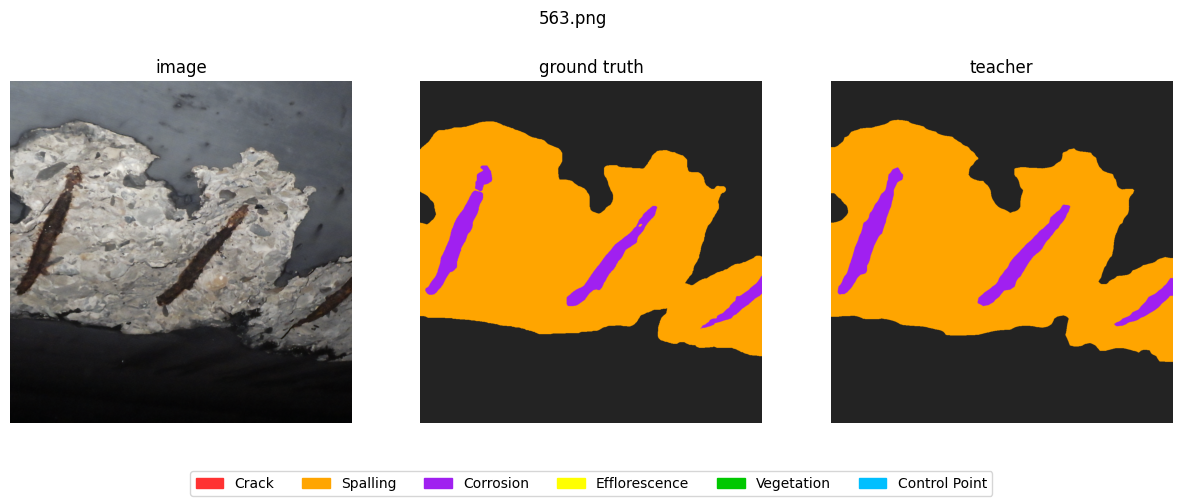

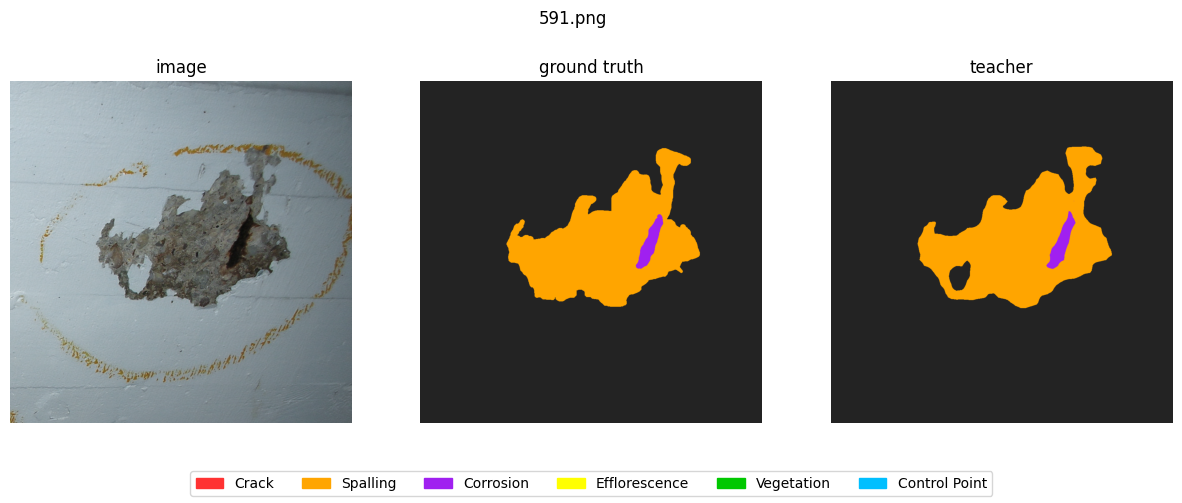

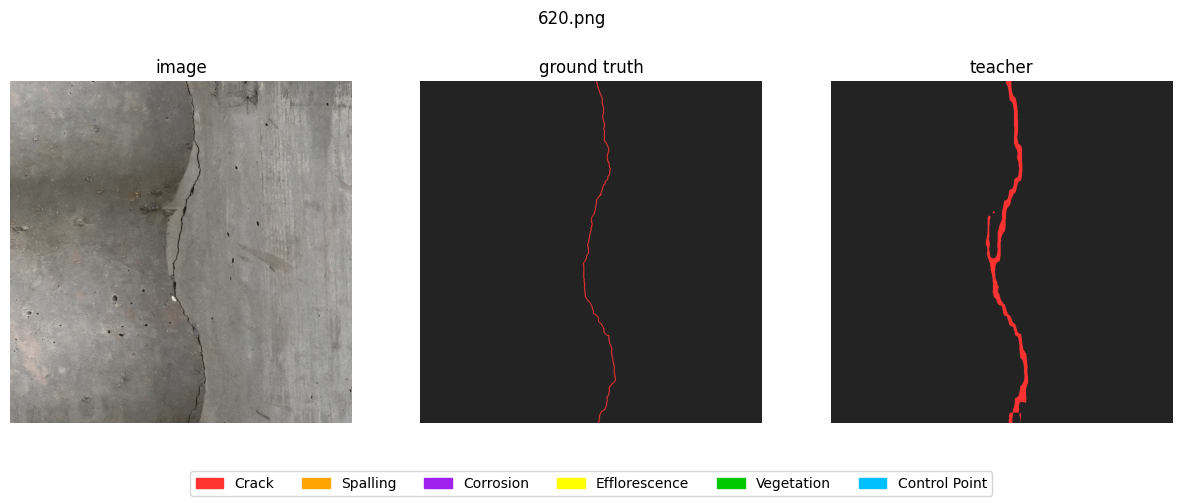

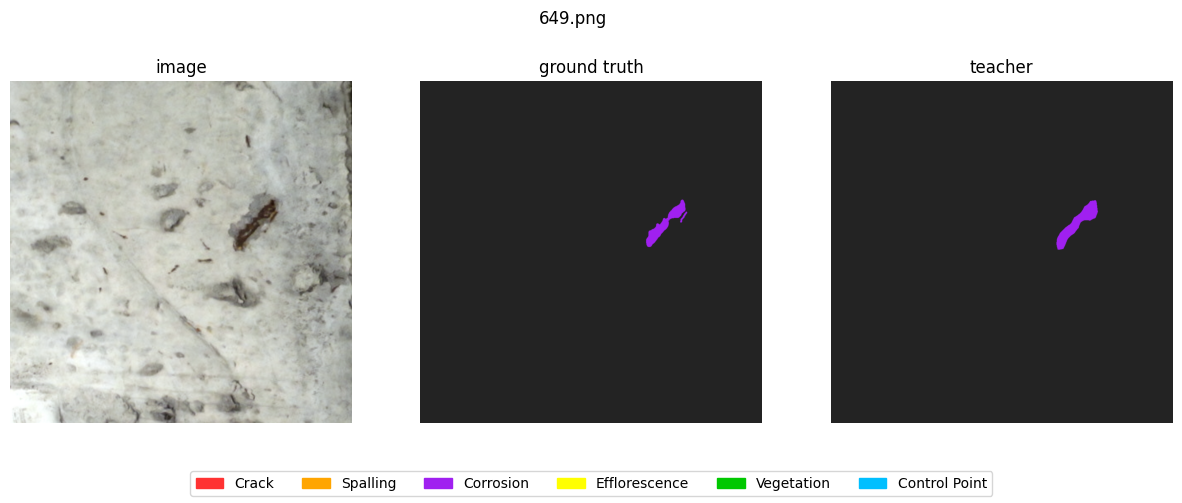

In [14]:
import glob, numpy as np, torch, matplotlib.pyplot as plt, matplotlib.patches as mpatches
from model import DINOv3MultiScaleSeg

CLASS_NAMES = ["Background", "Crack", "Spalling", "Corrosion", "Efflorescence", "Vegetation", "Control Point"]
PALETTE = np.array([[35, 35, 35], [255, 50, 50], [255, 165, 0], [160, 32, 240],
                    [255, 255, 0], [0, 200, 0], [0, 191, 255]], np.uint8)
LEGEND = [mpatches.Patch(color=PALETTE[c] / 255, label=CLASS_NAMES[c]) for c in range(1, 7)]

# check the dataset is present in THIS session before loading the 1.2 GB teacher
pairs = D.list_split("val")
print(f"dataset root: {D.ROOT} | {len(pairs)} val images")
assert pairs, ("No validation images found. The dataset is not in this Colab session: copy it into "
               "/content/s2ds_full (copy-from-Drive cell), re-run the setup cell, then this cell.")

sd = torch.load(f"{TEACHER_DIR}/teacher_best.pth", map_location="cpu", weights_only=False)["ema"]
has_backbone = any(k.startswith("backbone.") for k in sd)
teacher = DINOv3MultiScaleSeg(7, image_size=1024, pretrained=not has_backbone)
missing = teacher.load_state_dict(sd, strict=False).missing_keys
assert not any(k.startswith("head.") for k in missing), "head weights missing from checkpoint"
teacher = teacher.cuda().eval()
amp = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else None

# 4 example images spread evenly over however many val images there are
for i in np.linspace(0, len(pairs) - 1, 4).astype(int):
    img_path, lab_path = pairs[i]
    rgb = D._read_rgb(img_path)
    gt = D.lab2class(D._read_rgb(lab_path))
    x = torch.from_numpy(((rgb / 255.0 - D.IMAGENET_MEAN) / D.IMAGENET_STD).transpose(2, 0, 1)).float()[None].cuda()
    with torch.no_grad(), torch.autocast("cuda", dtype=amp, enabled=amp is not None):
        pred = teacher(x).float().argmax(1)[0].cpu().numpy()
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    for a, im, title in zip(ax, (rgb, PALETTE[gt], PALETTE[pred]), ("image", "ground truth", "teacher")):
        a.imshow(im); a.set_title(title); a.axis("off")
    fig.suptitle(os.path.basename(img_path))
    fig.legend(handles=LEGEND, loc="lower center", ncol=6); plt.show()
del teacher; torch.cuda.empty_cache()

## Next
Open **Notebook 2 (`2_Distill_Export_Pi.ipynb`)**. It reads `MyDrive/concrete_inspection/teacher/teacher_best.pth` automatically.